# Advertisement Click Prediction Using Machine Learning

## Project Overview

This project aims to develop a machine learning classification system to predict whether a user will click on an online advertisement based on demographic information, browsing behavior, and internet usage patterns.

The project follows an end-to-end machine learning workflow, including exploratory data analysis (EDA), data preprocessing, feature engineering, model training, hyperparameter tuning, and evaluation on unseen data.

## Business Problem

Online advertising is an important part of digital marketing. However, displaying advertisements to users who are unlikely to interact with them may reduce the efficiency of advertising campaigns.

Predicting advertisement clicks can help businesses better understand user behavior, improve audience targeting, and make more informed advertising decisions.

The objective is to develop a classification model that can distinguish between users who are likely to click on an advertisement and those who are not.

## Target Variable

The target variable is `Clicked on Ad`:

- `0` — The user did not click on the advertisement.
- `1` — The user clicked on the advertisement.

## Evaluation Strategy

This is a binary classification problem.

The primary evaluation metrics will include:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix

Because the dataset contains balanced target classes, accuracy is a useful metric. However, precision, recall, and F1-score will also be considered to provide a more complete assessment of model performance.

## Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

sns.set_theme(style='whitegrid')

## Data Overview

In [2]:
df = pd.read_csv('advertising.csv')
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1000, 10)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   str    
 5   City                      1000 non-null   str    
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   str    
 8   Timestamp                 1000 non-null   str    
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), str(4)
memory usage: 151.1 KB


### Data Understanding and Quality Assessment

Before performing exploratory data analysis, the dataset is examined to understand its structure, identify potential data quality issues, and verify the target variable.

The following checks are performed:

- Missing values
- Duplicate observations
- Data types
- Unique values in categorical features
- Target class distribution

In [7]:
print("Missing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:


Daily Time Spent on Site    0
Age                         0
Area Income                 0
Daily Internet Usage        0
Ad Topic Line               0
City                        0
Male                        0
Country                     0
Timestamp                   0
Clicked on Ad               0
dtype: int64


Duplicate Rows: 0


In [8]:
print("Unique Values per Column:")
display(df.nunique().sort_values(ascending=False))

print("\nTarget Values:")
print(df['Clicked on Ad'].unique())

print("\nMale Values:")
print(df['Male'].unique())

Unique Values per Column:


Ad Topic Line               1000
Area Income                 1000
Timestamp                   1000
City                         969
Daily Internet Usage         966
Daily Time Spent on Site     900
Country                      237
Age                           43
Male                           2
Clicked on Ad                  2
dtype: int64


Target Values:
[0 1]

Male Values:
[0 1]


In [5]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')

print("Timestamp dtype:", df['Timestamp'].dtype)

print("Invalid timestamps:", df['Timestamp'].isna().sum())

print("Date range:")
print(df['Timestamp'].min())
print(df['Timestamp'].max())

Timestamp dtype: datetime64[us]
Invalid timestamps: 0
Date range:
2016-01-01 02:52:10
2016-07-24 00:22:16


In [6]:
target_counts = df['Clicked on Ad'].value_counts().sort_index()

target_percentages = (df['Clicked on Ad'] .value_counts(normalize=True) .sort_index() * 100)

target_distribution = pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_percentages.round(2)
})

display(target_distribution)

,Count,Percentage
Clicked on Ad,,
0,500,50.0
1,500,50.0


### Data Quality Findings

- The dataset contains 1,000 observations and 10 columns.
- No missing values or duplicate records were identified.
- All timestamp values were successfully converted to datetime format.
- The dataset covers transactions recorded between January and July 2016.
- The target variable is perfectly balanced, with 500 observations in each class.
- `Ad Topic Line`, `City`, and `Country` contain high-cardinality categorical values and require further consideration during feature selection.
- No missing-value imputation or class rebalancing is currently required.

## Exploratory Data Analysis (EDA)

### Numerical Feature Analysis

This section examines the distributions, central tendencies, variability, and potential outliers of numerical features to better understand user behavior and identify patterns relevant to advertisement clicks.

In [7]:
numerical_features = ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage']

display(df[numerical_features].describe())

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,65.000200,36.009000,55000.000080,180.000100
std,15.853615,8.785562,13414.634022,43.902339
min,32.600000,19.000000,13996.500000,104.780000
25%,51.360000,29.000000,47031.802500,138.830000
50%,68.215000,35.000000,57012.300000,183.130000
75%,78.547500,42.000000,65470.635000,218.792500
max,91.430000,61.000000,79484.800000,269.960000


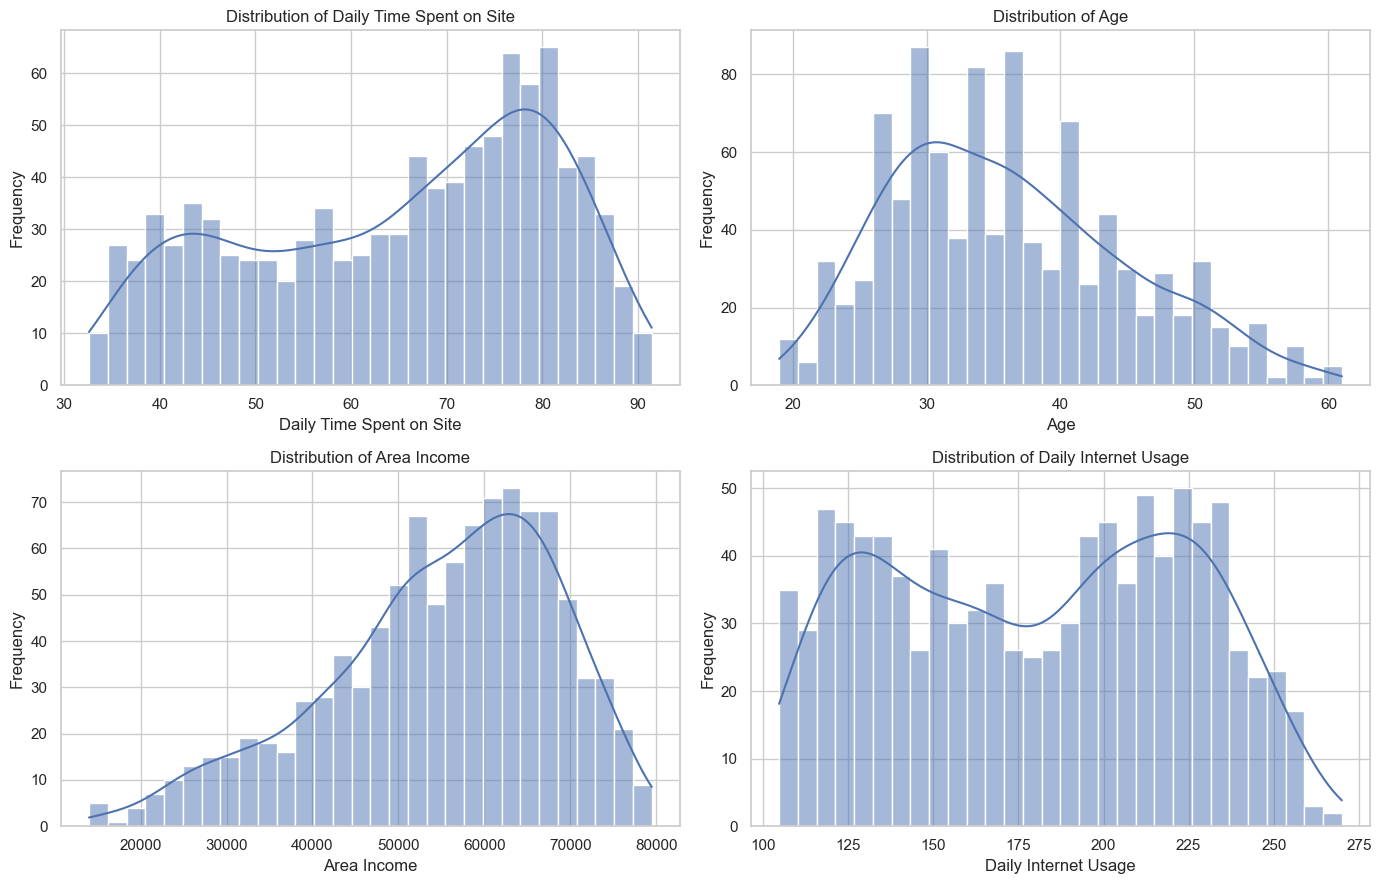

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, feature in zip(axes.flatten(), numerical_features):
    sns.histplot(data=df, x=feature, bins=30, kde=True, ax=ax)
    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Numerical Distribution Findings

- **Daily Time Spent on Site:** The distribution appears approximately bimodal, suggesting distinct patterns of website engagement.
- **Age:** Most users are concentrated around their 30s and early 40s, with a slightly right-skewed distribution.
- **Area Income:** The distribution is negatively skewed, with a longer tail toward lower income values.
- **Daily Internet Usage:** The distribution appears approximately bimodal, indicating different levels of internet activity among users.
- Several numerical features deviate from normality. Potential outliers will be investigated before making preprocessing decisions.
- Further analysis is required to determine how these features relate to advertisement clicks.

### Outlier Analysis

Boxplots are used to examine the spread of numerical features and identify potential outliers based on the interquartile range (IQR).

Potential outliers will not be removed automatically, as they may represent valid user behavior.

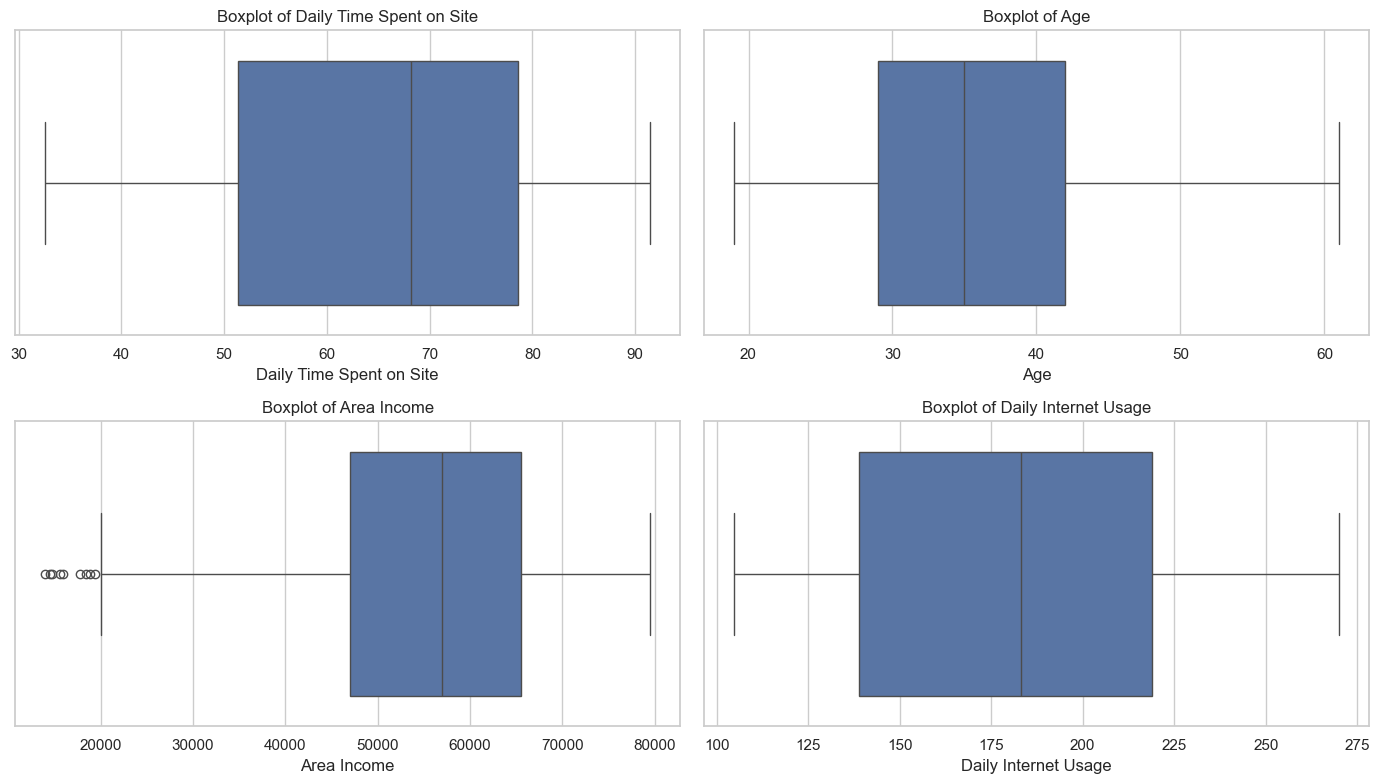

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, feature in zip(axes.flatten(), numerical_features):
    sns.boxplot(data=df, x=feature, ax=ax)
    ax.set_title(f'Boxplot of {feature}')
    ax.set_xlabel(feature)

plt.tight_layout()
plt.show()

In [14]:
outlier_summary = []

for feature in numerical_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ).sum()

    outlier_summary.append({
        'Feature': feature,
        'Outliers': outlier_count,
        'Percentage': round(outlier_count / len(df) * 100, 2)
    })

display(pd.DataFrame(outlier_summary))

,Feature,Outliers,Percentage
0,Daily Time Spent on Site,0,0.0
1,Age,0,0.0
2,Area Income,9,0.9
3,Daily Internet Usage,0,0.0


### Outlier Analysis Findings

- No potential outliers were detected in Daily Time Spent on Site, Age, or Daily Internet Usage using the IQR method.
- Area Income contains 9 potential lower-end outliers, representing 0.9% of the dataset.
- These observations may represent legitimate differences in users' socioeconomic characteristics.
- All observations were retained because there is no evidence that the identified outliers are erroneous.
- The impact of extreme values will be considered during model selection and preprocessing.

### Numerical Features vs. Advertisement Clicks

This section investigates how numerical features differ between users who clicked on an advertisement and those who did not.

Distribution plots and group-level summary statistics are used to identify potential relationships between user characteristics and advertisement-click behavior.

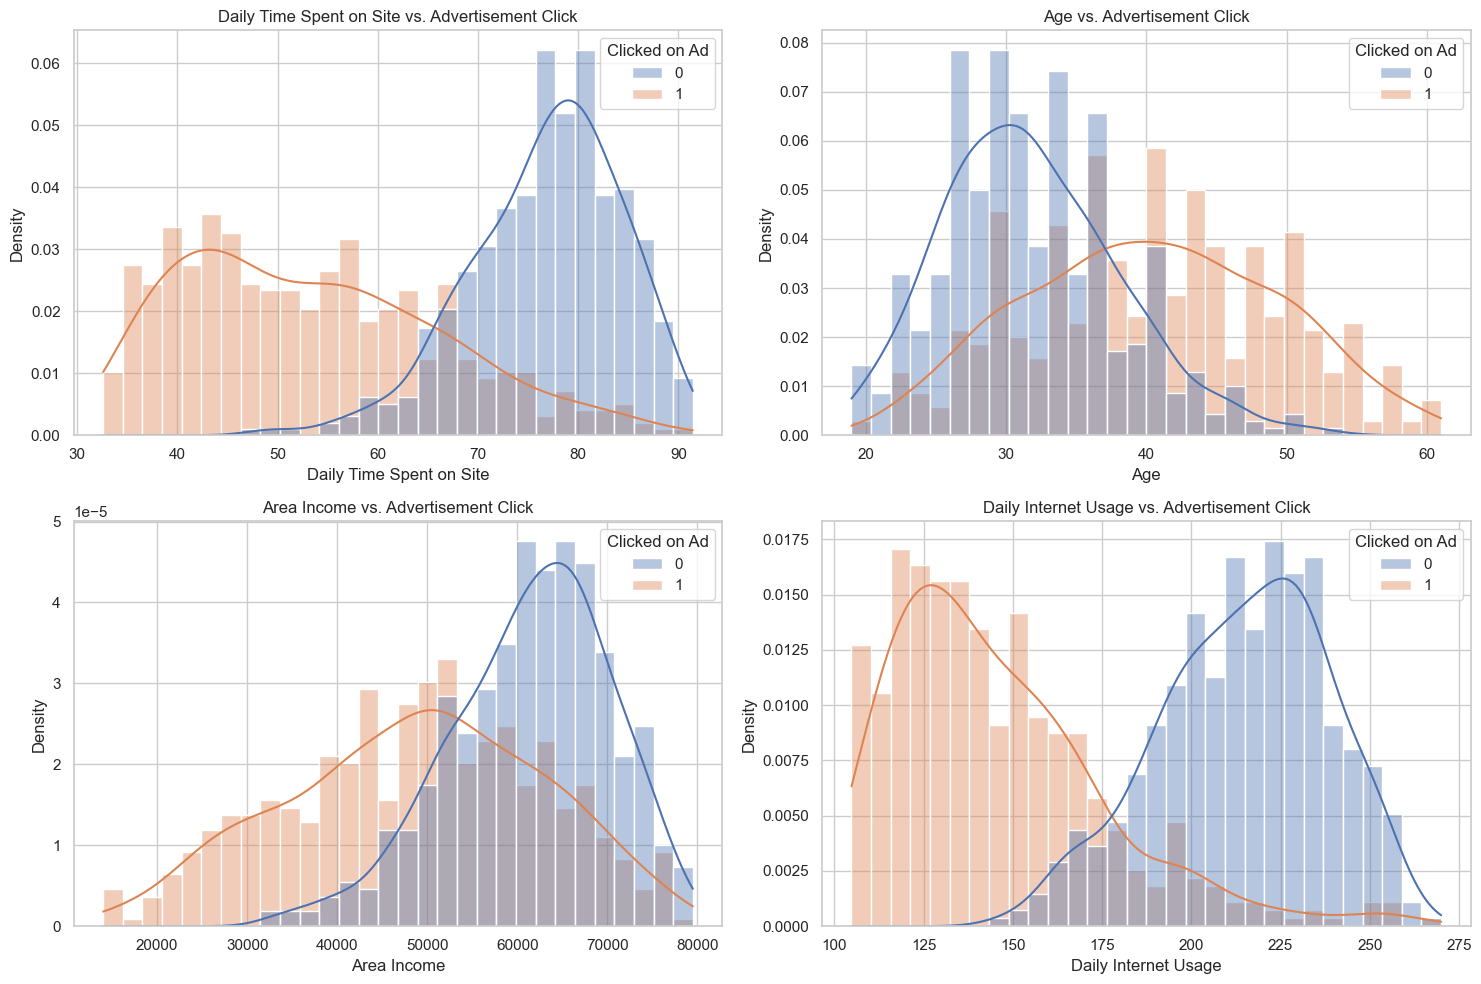

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, feature in zip(axes.flatten(), numerical_features):
    sns.histplot(data=df, x=feature, hue='Clicked on Ad', bins=30, kde=True, stat='density', common_norm=False, alpha=0.4, ax=ax)

    ax.set_title(f'{feature} vs. Advertisement Click')
    ax.set_xlabel(feature)
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

In [16]:
grouped_stats = (
    df.groupby('Clicked on Ad')[numerical_features]
    .agg(['mean', 'median', 'std'])
    .round(2)
)

display(grouped_stats)

Daily Time Spent on Site                  Age               \
                                  mean median    std   mean median   std   
Clicked on Ad                                                              
0                                76.85  77.65   7.56  31.68   31.0  6.21   
1                                53.15  51.53  12.82  40.33   40.0  8.86   

              Area Income                     Daily Internet Usage          \
                     mean    median       std                 mean  median   
Clicked on Ad                                                                
0                61385.59  62275.40   8904.06               214.51  216.36   
1                48614.41  49417.26  14116.24               145.49  138.79   

                      
                 std  
Clicked on Ad         
0              23.87  
1              30.03

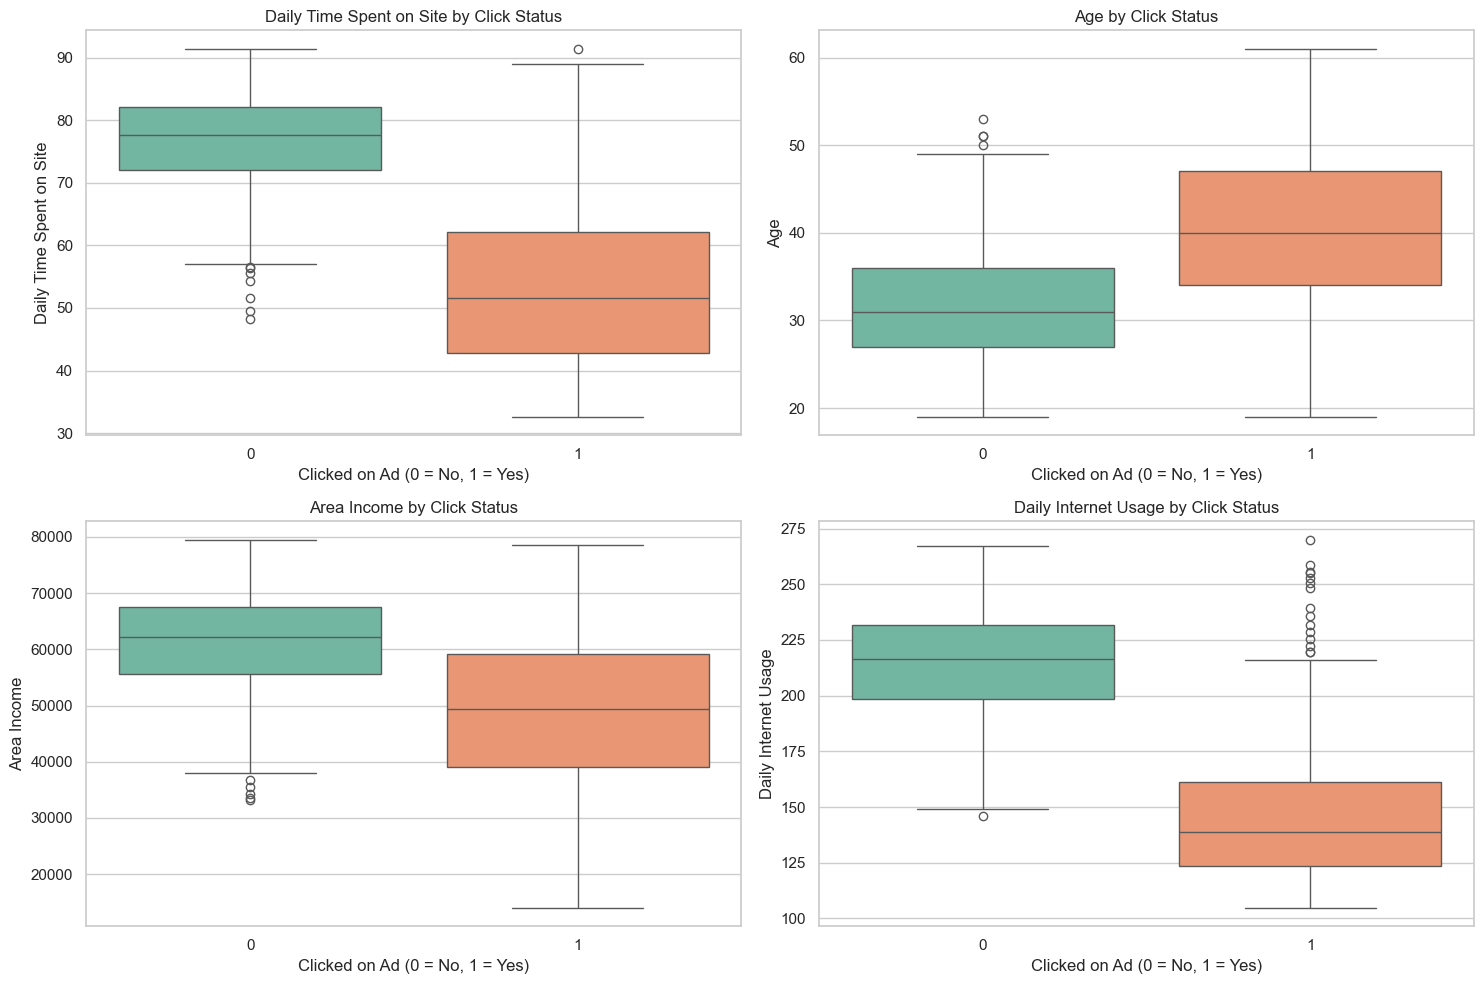

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, feature in zip(axes.flatten(), numerical_features):
    sns.boxplot(data=df, x='Clicked on Ad', y=feature, hue='Clicked on Ad', palette='Set2', legend=False, ax=ax)
    ax.set_title(f'{feature} by Click Status')
    ax.set_xlabel('Clicked on Ad (0 = No, 1 = Yes)')
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

### Numerical Features vs. Target — Key Findings

- **Daily Time Spent on Site:** Users who clicked on advertisements spent substantially less time on the website on average (53.15 vs. 76.85).
- **Age:** Users who clicked on advertisements were older on average (40.33 vs. 31.68), although the two distributions overlap.
- **Area Income:** Advertisement clicks were associated with lower average area income (48,614.41 vs. 61,385.59).
- **Daily Internet Usage:** Users who clicked on advertisements had considerably lower average daily internet usage (145.49 vs. 214.51).
- **Predictive Potential:** Daily Internet Usage and Daily Time Spent on Site show particularly clear separation between the target classes.
- **Outliers:** Some outliers appear in class-specific boxplots because the IQR boundaries are calculated separately for each class.
- These findings describe associations within the dataset and do not establish causal relationships.

### Categorical Features Analysis

This section explores categorical variables and their relationships with advertisement clicks.

The analysis begins with the binary `Male` feature, followed by an examination of high-cardinality categorical variables such as `Country`, `City`, and `Ad Topic Line`.

In [19]:
gender_click_counts = pd.crosstab(df['Male'], df['Clicked on Ad'])

display(gender_click_counts)

gender_click_rates = (pd.crosstab(
        df['Male'], df['Clicked on Ad'], normalize='index') * 100)

display(gender_click_rates.round(2))

Clicked on Ad,0,1
Male,,
0,250,269
1,250,231


Clicked on Ad,0,1
Male,,
0,48.17,51.83
1,51.98,48.02


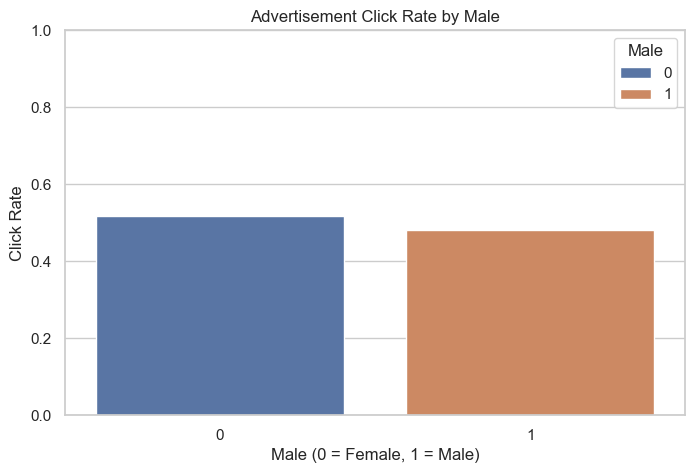

In [22]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Male', y='Clicked on Ad', hue='Male', errorbar=None)
plt.title('Advertisement Click Rate by Male')
plt.xlabel('Male (0 = Female, 1 = Male)')
plt.ylabel('Click Rate')
plt.ylim(0, 1)

plt.show()

### Gender-Based Click Analysis — Findings

- Female users (`Male = 0`) had an observed click rate of 51.83%.
- Male users (`Male = 1`) had an observed click rate of 48.02%.
- The difference between the groups was approximately 3.81 percentage points.
- The relatively small difference suggests that gender may have limited standalone predictive value.
- This descriptive comparison does not establish statistical significance or causality.
- The feature will be retained provisionally, with its predictive contribution and potential fairness implications assessed during modeling.

### High-Cardinality Categorical Feature Analysis

The dataset contains three categorical features with a large number of unique values: Country, City, and Ad Topic Line.

This analysis examines category frequencies and sparsity to assess whether these variables can be meaningfully incorporated into the predictive modeling pipeline.

In [8]:
categorical_features = ['Country', 'City', 'Ad Topic Line']

category_summary = []

for feature in categorical_features:
    counts = df[feature].value_counts()

    category_summary.append({
        'Feature': feature,
        'Unique Categories': df[feature].nunique(),
        'Most Frequent Category Count': counts.max(),
        'Categories Appearing Once': (counts == 1).sum()
    })

display(pd.DataFrame(category_summary))

,Feature,Unique Categories,Most Frequent Category Count,Categories Appearing Once
0,Country,237,9,14
1,City,969,3,940
2,Ad Topic Line,1000,1,1000


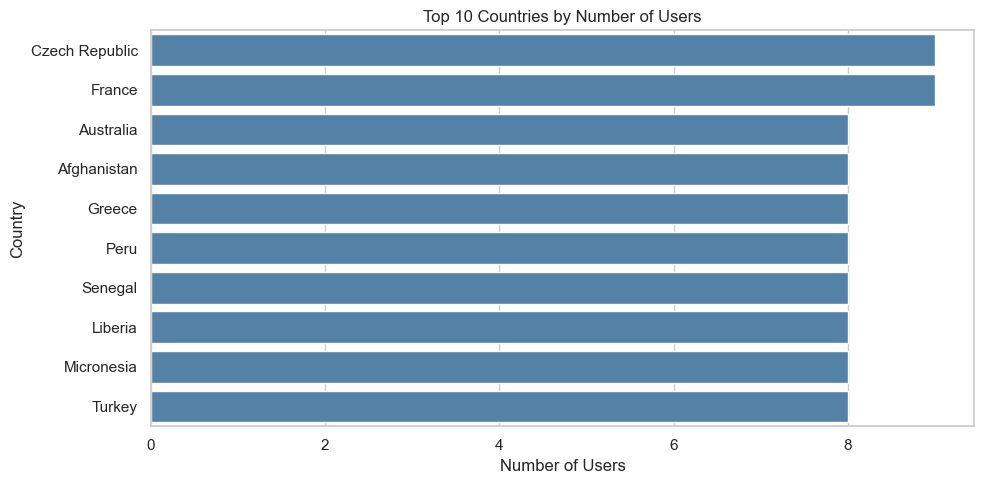

In [ ]:
top_countries = df['Country'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, color='steelblue')
plt.title('Top 10 Countries by Number of Users')
plt.xlabel('Number of Users')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

In [27]:
country_stats = (
    df.groupby('Country')['Clicked on Ad']
    .agg(Users='count', Click_Rate='mean')
    .reset_index())

country_stats['Click_Rate'] *= 100

countries_10_plus = (country_stats[country_stats['Users'] >= 10].sort_values('Click_Rate', ascending=False))

print("Countries with at least 10 users:", len(countries_10_plus))

display(countries_10_plus.head(10))

Countries with at least 10 users: 0


,Country,Users,Click_Rate


### High-Cardinality Categorical Features — Findings

- `Country` contains 237 unique categories, with no country represented by 10 or more observations.
- The most frequently occurring countries have only 8–9 observations each.
- The limited number of observations per country makes country-level click-rate comparisons unstable.
- `City` and `Ad Topic Line` also exhibit very high cardinality relative to the dataset size.
- These three features will be excluded from the initial baseline model to reduce complexity and avoid learning patterns from extremely sparse categories.
- Their potential predictive contribution may be investigated in future experiments using appropriate categorical encoding or text vectorization techniques.

### Temporal Feature Analysis

The `Timestamp` column contains the date and time associated with each observation.

This section explores whether advertisement-click behavior varies across different hours, days of the week, and months.

Temporal patterns are examined before deciding whether engineered time-based features should be included in the modeling pipeline.

In [9]:
df['Hour'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek
df['Month'] = df['Timestamp'].dt.month

display(df[['Timestamp', 'Hour', 'DayOfWeek', 'Month']].head())

,Timestamp,Hour,DayOfWeek,Month
0,2016-03-27 00:53:11,0,6,3
1,2016-04-04 01:39:02,1,0,4
2,2016-03-13 20:35:42,20,6,3
3,2016-01-10 02:31:19,2,6,1
4,2016-06-03 03:36:18,3,4,6


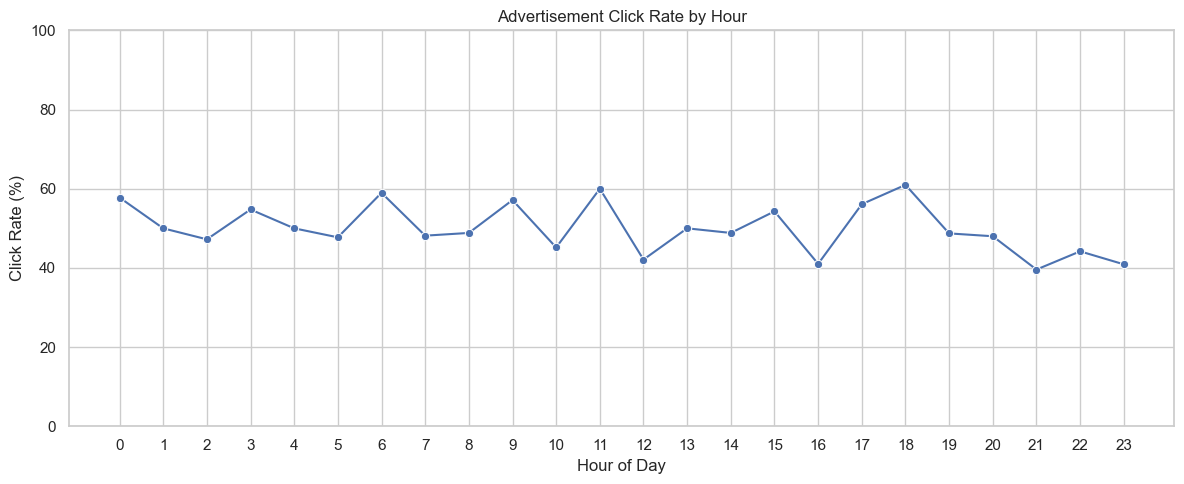

,Hour,mean,count
0,0,57.78,45
1,1,50.00,32
2,2,47.22,36
3,3,54.76,42
4,4,50.00,42
5,5,47.73,44
6,6,58.97,39
7,7,48.15,54
8,8,48.84,43
9,9,57.14,49


In [29]:
hourly_click_rate = (df.groupby('Hour')['Clicked on Ad'].agg(['mean', 'count']).reset_index())

hourly_click_rate['mean'] *= 100

plt.figure(figsize=(12, 5))
sns.lineplot(data=hourly_click_rate, x='Hour', y='mean', marker='o')

plt.title('Advertisement Click Rate by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Click Rate (%)')
plt.xticks(range(24))
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

display(hourly_click_rate.round(2))

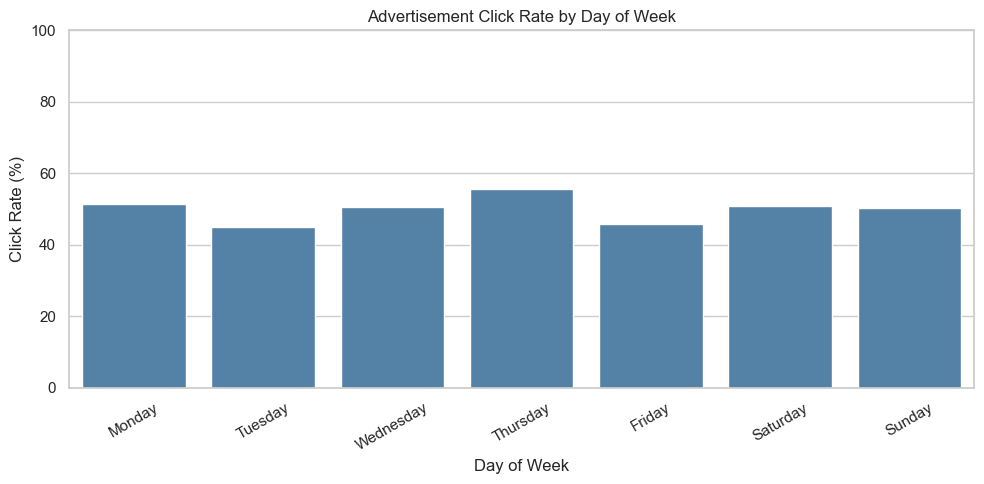

,mean,count
DayOfWeek,,
0,51.43,140
1,45.08,122
2,50.64,156
3,55.63,142
4,45.81,155
5,50.79,126
6,50.31,159


In [10]:
day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
             'Friday', 'Saturday', 'Sunday']

daily_click_rate = (
    df.groupby('DayOfWeek')['Clicked on Ad']
    .agg(['mean', 'count'])
    .reindex(range(7))
)

daily_click_rate['mean'] *= 100

plt.figure(figsize=(10, 5))
sns.barplot(x=day_names, y=daily_click_rate['mean'].values, color='steelblue')
plt.title('Advertisement Click Rate by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Click Rate (%)')
plt.ylim(0, 100)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

display(daily_click_rate.round(2))

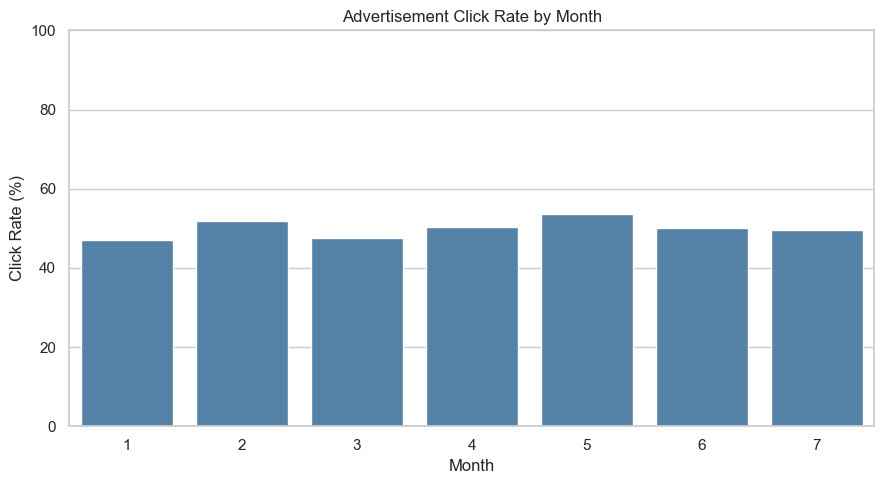

,mean,count
Month,,
1,46.94,147
2,51.88,160
3,47.44,156
4,50.34,147
5,53.74,147
6,50.00,142
7,49.50,101


In [11]:
monthly_click_rate = (
    df.groupby('Month')['Clicked on Ad']
    .agg(['mean', 'count'])
)

monthly_click_rate['mean'] *= 100

plt.figure(figsize=(9, 5))
sns.barplot(x=monthly_click_rate.index, y=monthly_click_rate['mean'].values, color='steelblue')
plt.title('Advertisement Click Rate by Month')
plt.xlabel('Month')
plt.ylabel('Click Rate (%)')
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

display(monthly_click_rate.round(2))

### Temporal Feature Analysis — Key Findings

- **Hour:** Advertisement click rates varied throughout the day, ranging from 39.58% to 60.98%. However, no consistent hourly pattern was observed.
- **Day of Week:** Thursday had the highest observed click rate (55.63%), while Tuesday had the lowest (45.08%). Most days remained close to the overall click rate of 50%.
- **Month:** Monthly click rates ranged from 46.94% in January to 53.74% in May, suggesting relatively limited monthly variation.
- **Sample Size:** Some hourly groups contain relatively few observations, making their click-rate estimates less stable.
- **Feature Engineering:** Hour, DayOfWeek, and Month will be retained as candidate features and evaluated during model development.
- The observed temporal differences do not establish statistically significant or causal relationships.

### Correlation Analysis

Pearson correlation analysis is performed to examine linear relationships among numerical features and the target variable.

The analysis aims to identify potentially informative predictors and detect strong correlations between input features.

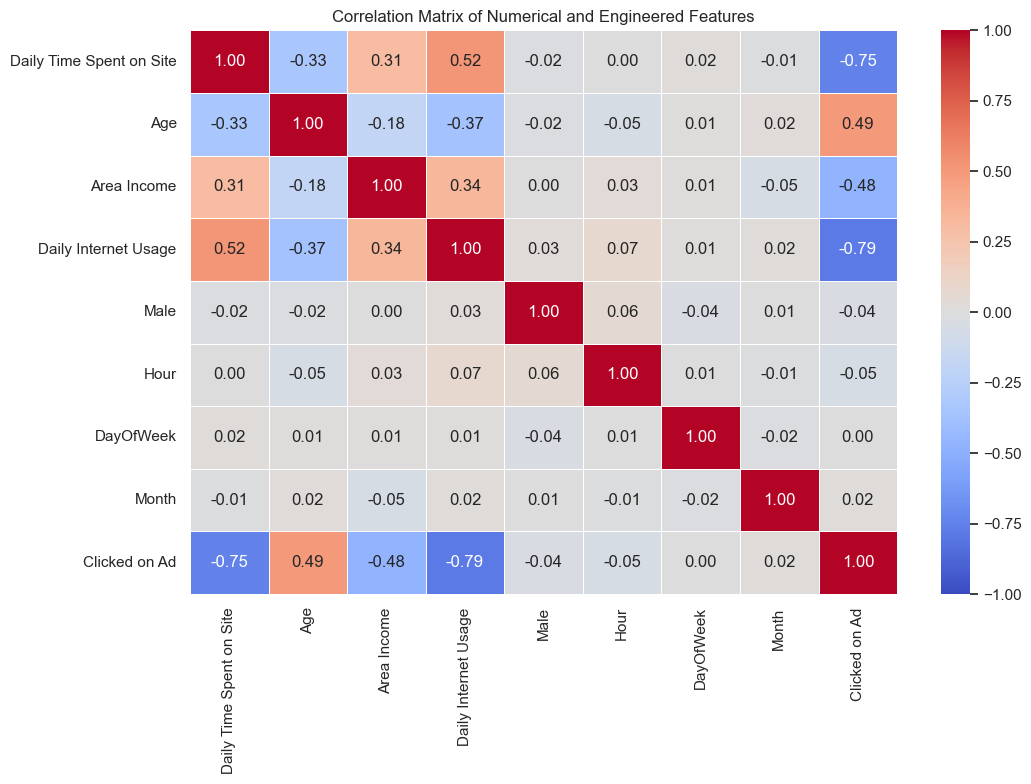

In [32]:
correlation_features = numerical_features + ['Male', 'Hour', 'DayOfWeek', 'Month', 'Clicked on Ad']

corr_matrix = df[correlation_features].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Numerical and Engineered Features')

plt.tight_layout()
plt.show()

In [33]:
target_correlations = (
    corr_matrix['Clicked on Ad']
    .drop('Clicked on Ad')
    .sort_values(key=abs, ascending=False)
)

display(target_correlations.to_frame('Correlation with Target'))

,Correlation with Target
Daily Internet Usage,-0.786539
Daily Time Spent on Site,-0.748117
Age,0.492531
Area Income,-0.476255
Hour,-0.047431
Male,-0.038027
Month,0.016095
DayOfWeek,0.002003


### Correlation Analysis — Key Findings

- **Daily Internet Usage** showed the strongest negative correlation with advertisement clicks (r = -0.787).
- **Daily Time Spent on Site** also demonstrated a strong negative correlation with the target (r = -0.748).
- **Age** exhibited a moderate positive correlation (r = 0.493).
- **Area Income** showed a moderate negative correlation (r = -0.476).
- **Male, Hour, DayOfWeek, and Month** had weak linear correlations with the target.
- Daily Internet Usage and Daily Time Spent on Site were moderately correlated with each other (r = 0.52), but no severe pairwise correlation was observed among the predictors.
- Behavioral features appear particularly promising for advertisement-click prediction.
- Correlation analysis alone cannot establish feature importance, causality, or the presence of nonlinear predictive relationships.

## EDA Summary and Modeling Decisions

The exploratory data analysis revealed several important findings:

### Data Quality
- The dataset contains 1,000 observations and 10 original columns.
- No missing values or duplicate records were found.
- The target variable is perfectly balanced (50% clicked, 50% not clicked).

### Numerical Features
- Daily Internet Usage and Daily Time Spent on Site showed the strongest associations with advertisement clicks.
- Age and Area Income demonstrated moderate relationships with the target.
- Nine potential outliers were detected in Area Income and retained.

### Categorical Features
- The Male feature showed only a small difference in observed click rates between groups.
- Country, City, and Ad Topic Line exhibited high cardinality and will be excluded from the initial baseline model.

### Temporal Features
- Hourly, weekly, and monthly click rates showed some variation, but no consistent temporal pattern was identified.
- Engineered temporal features will be evaluated in a separate modeling experiment.

### Modeling Strategy
- Begin with four numerical predictors and the Male feature.
- Compare the baseline with an extended feature set containing Hour, DayOfWeek, and Month.
- Use stratified data splitting to preserve the target distribution.
- Apply preprocessing within machine learning pipelines to reduce data leakage.
- Compare classification algorithms using validation data.
- Reserve the test set for final evaluation.

## Data Preparation

### Feature Selection and Target Definition

The initial baseline model will use four numerical predictors and one binary predictor.

High-cardinality categorical variables and engineered temporal variables will be excluded from the initial baseline.

The target variable is `Clicked on Ad`.

In [12]:
# Sort observations chronologically
df_sorted = df.sort_values('Timestamp').reset_index(drop=True)

# Define feature sets
baseline_features = ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male']

temporal_features = ['Hour', 'DayOfWeek', 'Month']

feature_columns = baseline_features + temporal_features

X = df_sorted[feature_columns].copy()
y = df_sorted['Clicked on Ad'].astype(int)

# Chronological split boundaries
train_end = int(len(df_sorted) * 0.64)
val_end = int(len(df_sorted) * 0.80)

X_train = X.iloc[:train_end].copy()
X_val = X.iloc[train_end:val_end].copy()
X_test = X.iloc[val_end:].copy()

y_train = y.iloc[:train_end].copy()
y_val = y.iloc[train_end:val_end].copy()
y_test = y.iloc[val_end:].copy()

# Display results
for name, X_split, y_split in [
    ('Training', X_train, y_train),
    ('Validation', X_val, y_val),
    ('Testing', X_test, y_test)
]:
    print(f'\n{name}: {X_split.shape}')
    print('Class Distribution:')
    print(y_split.value_counts(normalize=True).sort_index().round(3))


Training: (640, 8)
Class Distribution:
Clicked on Ad
0    0.505
1    0.495
Name: proportion, dtype: float64

Validation: (160, 8)
Class Distribution:
Clicked on Ad
0    0.519
1    0.481
Name: proportion, dtype: float64

Testing: (200, 8)
Class Distribution:
Clicked on Ad
0    0.47
1    0.53
Name: proportion, dtype: float64


In [13]:
print("Training period:",
      df_sorted.iloc[:train_end]['Timestamp'].min(),
      "to",
      df_sorted.iloc[:train_end]['Timestamp'].max())

print("\nValidation period:",
      df_sorted.iloc[train_end:val_end]['Timestamp'].min(),
      "to",
      df_sorted.iloc[train_end:val_end]['Timestamp'].max())

print("\nTesting period:",
      df_sorted.iloc[val_end:]['Timestamp'].min(),
      "to",
      df_sorted.iloc[val_end:]['Timestamp'].max())

Training period: 2016-01-01 02:52:10 to 2016-05-08 10:25:08

Validation period: 2016-05-08 12:08:26 to 2016-06-11 06:47:55

Testing period: 2016-06-11 08:38:16 to 2016-07-24 00:22:16


### Chronological Data Splitting

The dataset was sorted chronologically using the Timestamp column and divided into three non-overlapping subsets:

- Training set: 640 observations (64%)
- Validation set: 160 observations (16%)
- Test set: 200 observations (20%)

The target distribution remained approximately balanced across all three subsets.

A chronological split was selected to evaluate the model's ability to generalize from earlier observations to later ones. The test set will remain untouched until final model evaluation.

## Data Preprocessing

A preprocessing pipeline is constructed to prepare the input features for machine learning.

- Numerical features are standardized using StandardScaler.
- The binary Male feature is passed through without transformation.
- No missing-value imputation is required because the dataset contains no missing values.
- Preprocessing parameters are learned exclusively from the training data to prevent data leakage.

The preprocessing pipeline will be integrated with classification models during training.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

numerical_features = ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage']

binary_features = ['Male']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('binary', 'passthrough', binary_features)
    ],
    remainder='drop'
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [15]:
X_train_baseline = X_train[baseline_features]
X_train_processed = preprocessor.fit_transform(X_train_baseline)

print("Original shape:", X_train_baseline.shape)
print("Processed shape:", X_train_processed.shape)

print("Missing values:", np.isnan(X_train_processed).sum())
print("Infinite values:", np.isinf(X_train_processed).sum())

Original shape: (640, 5)
Processed shape: (640, 5)
Missing values: 0
Infinite values: 0


## Model Development and Evaluation

### Baseline Model — Logistic Regression

Logistic Regression is used as the initial baseline classifier for predicting advertisement clicks.


The baseline model is evaluated on the chronological validation set using Accuracy, Precision, Recall, F1-score, ROC-AUC, and a Confusion Matrix.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [18]:
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000, random_state=42
    ))
])

log_reg_pipeline.fit(X_train[baseline_features], y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [19]:
X_val_baseline = X_val[baseline_features]

y_val_pred_lr = log_reg_pipeline.predict(X_val_baseline)

y_val_proba_lr = log_reg_pipeline.predict_proba(X_val_baseline)[:, 1]

print("Predictions:", y_val_pred_lr[:10])
print("Probabilities:", y_val_proba_lr[:10])

Predictions: [0 1 0 0 1 0 0 1 1 1]
Probabilities: [0.00450115 0.9981875  0.00577044 0.01021125 0.99919475 0.16963222
 0.26447121 0.9927543  0.9991861  0.98697467]


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

lr_metrics = {
    'Accuracy': accuracy_score(y_val, y_val_pred_lr),
    'Precision': precision_score(y_val, y_val_pred_lr),
    'Recall': recall_score(y_val, y_val_pred_lr),
    'F1-score': f1_score(y_val, y_val_pred_lr),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_lr)
}

print("Logistic Regression — Validation Metrics")

display(pd.DataFrame([lr_metrics], index=['Logistic Regression']).round(4))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_lr))

Logistic Regression — Validation Metrics


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.9625,0.9863,0.9351,0.96,0.984



Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96        83
           1       0.99      0.94      0.96        77

    accuracy                           0.96       160
   macro avg       0.96      0.96      0.96       160
weighted avg       0.96      0.96      0.96       160


Confusion Matrix:
[[82  1]
 [ 5 72]]


### Logistic Regression — Validation Results

The baseline Logistic Regression model achieved strong performance on the chronological validation set:

- Accuracy: 96.25%
- Precision: 98.63%
- Recall: 93.51%
- F1-score: 96.00%
- ROC-AUC: 98.40%

The confusion matrix showed 82 true negatives, 72 true positives, 1 false positive, and 5 false negatives.

The model demonstrated excellent precision, with slightly lower recall, indicating that some users who clicked on advertisements were incorrectly classified as non-clickers.

These results establish a strong baseline for comparison with more complex classification algorithms.

The test set remains untouched.

### Decision Tree Classifier

A Decision Tree classifier is trained to capture nonlinear relationships and interactions among user features.

Unlike Logistic Regression, Decision Trees do not require feature scaling.

The initial model uses regularization parameters to limit tree complexity and reduce the risk of overfitting.

Its performance is evaluated on the chronological validation set and compared with the Logistic Regression baseline.

In [21]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=42)

dt_model.fit(X_train[baseline_features], y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [22]:
X_val_baseline = X_val[baseline_features]

y_val_pred_dt = dt_model.predict(X_val_baseline)
y_val_proba_dt = dt_model.predict_proba(X_val_baseline)[:, 1]

dt_metrics = {
    'Accuracy': accuracy_score(y_val, y_val_pred_dt),
    'Precision': precision_score(y_val, y_val_pred_dt, zero_division=0),
    'Recall': recall_score(y_val, y_val_pred_dt),
    'F1-score': f1_score(y_val, y_val_pred_dt),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_dt)
}

display(
    pd.DataFrame(
        [dt_metrics],
        index=['Decision Tree']
    ).round(4)
)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_dt))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Decision Tree,0.925,0.9452,0.8961,0.92,0.9443



Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.95      0.93        83
           1       0.95      0.90      0.92        77

    accuracy                           0.93       160
   macro avg       0.93      0.92      0.92       160
weighted avg       0.93      0.93      0.92       160


Confusion Matrix:
[[79  4]
 [ 8 69]]


### Decision Tree — Validation Results

The Decision Tree classifier achieved the following performance:

- Accuracy: 92.50%
- Precision: 94.52%
- Recall: 89.61%
- F1-score: 92.00%
- ROC-AUC: 94.43%

The confusion matrix showed 79 true negatives, 69 true positives, 4 false positives, and 8 false negatives.

Compared with Logistic Regression, the Decision Tree achieved lower performance across all evaluation metrics.

Logistic Regression remains the strongest baseline model so far, achieving an F1-score of 96.00% and ROC-AUC of 98.40%.

Further experiments with ensemble methods will determine whether more complex models can improve predictive performance.

### Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to improve predictive stability and generalization.

Each tree is trained using bootstrap samples, while random subsets of features are considered during node splitting.

The Random Forest model is evaluated on the chronological validation set using the same metrics as the previous classifiers.

Its performance will be compared with Logistic Regression and Decision Tree.

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train[baseline_features], y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [24]:
y_val_pred_rf = rf_model.predict(X_val[baseline_features])

y_val_proba_rf = rf_model.predict_proba(X_val[baseline_features])[:, 1]

rf_metrics = {
    'Accuracy': accuracy_score(y_val, y_val_pred_rf),
    'Precision': precision_score(y_val, y_val_pred_rf, zero_division=0),
    'Recall': recall_score(y_val, y_val_pred_rf),
    'F1-score': f1_score(y_val, y_val_pred_rf),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_rf)
}

display(pd.DataFrame([rf_metrics],index=['Random Forest']).round(4))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Random Forest,0.95,0.9726,0.9221,0.9467,0.9869



Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.95        83
           1       0.97      0.92      0.95        77

    accuracy                           0.95       160
   macro avg       0.95      0.95      0.95       160
weighted avg       0.95      0.95      0.95       160


Confusion Matrix:
[[81  2]
 [ 6 71]]


In [25]:
model_comparison = pd.DataFrame(
    [lr_metrics, dt_metrics, rf_metrics],
    index=[
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ]
)

display(
    model_comparison.sort_values(
        by='F1-score',
        ascending=False
    ).round(4)
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.9625,0.9863,0.9351,0.9600,0.9840
Random Forest,0.9500,0.9726,0.9221,0.9467,0.9869
Decision Tree,0.9250,0.9452,0.8961,0.9200,0.9443


### Random Forest — Validation Results

The Random Forest classifier achieved the following results:

- Accuracy: 95.00%
- Precision: 97.26%
- Recall: 92.21%
- F1-score: 94.67%
- ROC-AUC: 98.69%

The confusion matrix showed 81 true negatives, 71 true positives, 2 false positives, and 6 false negatives.

Random Forest outperformed Decision Tree across all evaluation metrics and achieved the highest ROC-AUC among the three models.

However, Logistic Regression maintained the highest F1-score, accuracy, precision, and recall.

The results suggest that both Logistic Regression and Random Forest are promising candidates for further experimentation.

The final model has not yet been selected.

### Support Vector Machine (SVM)

A Support Vector Classifier with an RBF kernel is trained to capture potentially nonlinear decision boundaries.

Numerical features are standardized using a preprocessing pipeline, since SVM is sensitive to feature scales.

The model is evaluated on the chronological validation set using the same metrics as the previous classifiers.

In [26]:
from sklearn.svm import SVC
from sklearn.base import clone

svm_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        random_state=42
    ))
])

svm_pipeline.fit(X_train[baseline_features], y_train)

print("SVM trained successfully.")

SVM trained successfully.


In [27]:
y_val_pred_svm = svm_pipeline.predict(X_val[baseline_features])

y_val_scores_svm = svm_pipeline.decision_function(X_val[baseline_features])

svm_metrics = {
    'Accuracy': accuracy_score(y_val, y_val_pred_svm),
    'Precision': precision_score(y_val, y_val_pred_svm, zero_division=0),
    'Recall': recall_score(y_val, y_val_pred_svm),
    'F1-score': f1_score(y_val, y_val_pred_svm),
    'ROC-AUC': roc_auc_score(y_val, y_val_scores_svm)
}

display(pd.DataFrame([svm_metrics], index=['SVM']).round(4))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_svm))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
SVM,0.9625,0.9863,0.9351,0.96,0.9903



Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96        83
           1       0.99      0.94      0.96        77

    accuracy                           0.96       160
   macro avg       0.96      0.96      0.96       160
weighted avg       0.96      0.96      0.96       160


Confusion Matrix:
[[82  1]
 [ 5 72]]


In [28]:
model_comparison = pd.DataFrame(
    [lr_metrics, dt_metrics, rf_metrics, svm_metrics],
    index=[
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM'
    ]
)

display(model_comparison.sort_values(by='F1-score',ascending=False).round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.9625,0.9863,0.9351,0.9600,0.9840
SVM,0.9625,0.9863,0.9351,0.9600,0.9903
Random Forest,0.9500,0.9726,0.9221,0.9467,0.9869
Decision Tree,0.9250,0.9452,0.8961,0.9200,0.9443


### K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a distance-based classification algorithm that predicts the class of a new observation based on its nearest training examples.

Since KNN is sensitive to differences in feature scales, numerical features are standardized using StandardScaler within a preprocessing pipeline.

An initial KNN classifier with five neighbors is trained and evaluated on the chronological validation set.

Its performance is compared with the previously trained classification models.

In [29]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone

knn_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        weights='uniform',
        metric='minkowski',
        p=2
    ))
])

knn_pipeline.fit(X_train[baseline_features],y_train)

print("KNN trained successfully.")

KNN trained successfully.


In [ ]:
y_val_pred_knn = knn_pipeline.predict(X_val[baseline_features])

y_val_proba_knn = knn_pipeline.predict_proba(X_val[baseline_features])[:, 1]

knn_metrics = {
    'Accuracy': accuracy_score(y_val, y_val_pred_knn),
    'Precision': precision_score(y_val, y_val_pred_knn, zero_division=0),
    'Recall': recall_score(y_val, y_val_pred_knn),
    'F1-score': f1_score(y_val, y_val_pred_knn),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_knn)
}

display(
    pd.DataFrame(
        [knn_metrics],
        index=['KNN']
    ).round(4)
)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_knn))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
KNN,0.9625,0.9863,0.9351,0.96,0.9757



Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96        83
           1       0.99      0.94      0.96        77

    accuracy                           0.96       160
   macro avg       0.96      0.96      0.96       160
weighted avg       0.96      0.96      0.96       160


Confusion Matrix:
[[82  1]
 [ 5 72]]


In [31]:
model_comparison = pd.DataFrame(
    [
        lr_metrics,
        dt_metrics,
        rf_metrics,
        svm_metrics,
        knn_metrics
    ],
    index=[
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'KNN'
    ]
)

display(
    model_comparison.sort_values(
        by='F1-score',
        ascending=False
    ).round(4)
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.9625,0.9863,0.9351,0.9600,0.9840
KNN,0.9625,0.9863,0.9351,0.9600,0.9757
SVM,0.9625,0.9863,0.9351,0.9600,0.9903
Random Forest,0.9500,0.9726,0.9221,0.9467,0.9869
Decision Tree,0.9250,0.9452,0.8961,0.9200,0.9443


### K-Nearest Neighbors — Validation Results

The K-Nearest Neighbors classifier achieved:

- Accuracy: 96.25%
- Precision: 98.63%
- Recall: 93.51%
- F1-score: 96.00%
- ROC-AUC: 97.57%

The confusion matrix showed 82 true negatives, 72 true positives, 1 false positive, and 5 false negatives.

KNN matched Logistic Regression and SVM in threshold-based classification performance but achieved a lower ROC-AUC.

SVM currently has the highest ROC-AUC, while Logistic Regression, SVM, and KNN share the highest F1-score.

Further experiments are required before selecting the final model.

### Gradient Boosting Classifier

Gradient Boosting is an ensemble learning method that builds Decision Trees sequentially to minimize prediction errors.

Unlike Random Forest, which combines independently trained trees, Gradient Boosting iteratively improves the model by fitting new trees to the negative gradients of the loss function.

The model is trained using the baseline features and evaluated on the chronological validation set.

Its performance is compared with the previously trained classification algorithms.

In [32]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train[baseline_features],y_train)

print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


In [ ]:
y_val_pred_gb = gb_model.predict(X_val[baseline_features])

y_val_proba_gb = gb_model.predict_proba(X_val[baseline_features])[:, 1]

gb_metrics = {
    'Accuracy': accuracy_score(y_val, y_val_pred_gb),
    'Precision': precision_score(y_val, y_val_pred_gb, zero_division=0),
    'Recall': recall_score(y_val, y_val_pred_gb),
    'F1-score': f1_score(y_val, y_val_pred_gb),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_gb)
}

display(pd.DataFrame([gb_metrics],index=['Gradient Boosting']).round(4))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_gb))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Gradient Boosting,0.95,0.9726,0.9221,0.9467,0.9815



Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.95        83
           1       0.97      0.92      0.95        77

    accuracy                           0.95       160
   macro avg       0.95      0.95      0.95       160
weighted avg       0.95      0.95      0.95       160


Confusion Matrix:
[[81  2]
 [ 6 71]]


In [34]:
model_comparison = pd.DataFrame(
    [
        lr_metrics,
        dt_metrics,
        rf_metrics,
        svm_metrics,
        knn_metrics,
        gb_metrics
    ],
    index=[
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'KNN',
        'Gradient Boosting'
    ]
)

display(
    model_comparison.sort_values(
        by=['F1-score', 'ROC-AUC'],
        ascending=False
    ).round(4)
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
SVM,0.9625,0.9863,0.9351,0.9600,0.9903
Logistic Regression,0.9625,0.9863,0.9351,0.9600,0.9840
KNN,0.9625,0.9863,0.9351,0.9600,0.9757
Random Forest,0.9500,0.9726,0.9221,0.9467,0.9869
Gradient Boosting,0.9500,0.9726,0.9221,0.9467,0.9815
Decision Tree,0.9250,0.9452,0.8961,0.9200,0.9443


### Gradient Boosting Results and Initial Model Comparison

The Gradient Boosting classifier achieved:

- Accuracy: 95.00%
- Precision: 97.26%
- Recall: 92.21%
- F1-score: 94.67%
- ROC-AUC: 98.15%

Its confusion matrix contained 81 true negatives, 71 true positives, 2 false positives, and 6 false negatives.

Across the six baseline models, Logistic Regression, SVM, and KNN achieved the highest F1-score of 96.00%.

SVM achieved the highest ROC-AUC of 99.03%, followed by Random Forest at 98.69%.

These results demonstrate that more complex ensemble models do not necessarily outperform simpler classifiers.

Logistic Regression and SVM are the leading candidates for further optimization. However, no final model has been selected, and the test set remains untouched.

### XGBoost Classifier

XGBoost (Extreme Gradient Boosting) is an optimized gradient boosting algorithm that builds decision trees sequentially to minimize prediction errors.

It incorporates regularization techniques to control model complexity and improve generalization.

The model is trained using the baseline features and evaluated on the chronological validation set using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

In [35]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train[baseline_features],y_train)

print("XGBoost trained successfully.")

XGBoost trained successfully.


In [36]:
y_val_pred_xgb = xgb_model.predict(X_val[baseline_features])

y_val_proba_xgb = xgb_model.predict_proba(X_val[baseline_features])[:, 1]

xgb_metrics = {
    'Accuracy': accuracy_score(y_val, y_val_pred_xgb),
    'Precision': precision_score(
        y_val, y_val_pred_xgb, zero_division=0
    ),
    'Recall': recall_score(y_val, y_val_pred_xgb),
    'F1-score': f1_score(y_val, y_val_pred_xgb),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_xgb)
}

display(pd.DataFrame([xgb_metrics],index=['XGBoost']).round(4))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_xgb))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
XGBoost,0.9438,0.9595,0.9221,0.9404,0.9859



Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.95        83
           1       0.96      0.92      0.94        77

    accuracy                           0.94       160
   macro avg       0.94      0.94      0.94       160
weighted avg       0.94      0.94      0.94       160


Confusion Matrix:
[[80  3]
 [ 6 71]]


### AdaBoost Classifier

AdaBoost (Adaptive Boosting) is an ensemble learning algorithm that combines multiple weak learners into a stronger classifier.

It sequentially adjusts the importance of training observations, placing greater emphasis on samples that were incorrectly classified in previous iterations.

The model is trained using the baseline features and evaluated on the chronological validation set.

Its performance is compared with the other classification algorithms.

In [37]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.05,
    random_state=42
)

ada_model.fit(X_train[baseline_features],y_train)

print("AdaBoost trained successfully.")

AdaBoost trained successfully.


In [38]:
y_val_pred_ada = ada_model.predict(X_val[baseline_features])

y_val_proba_ada = ada_model.predict_proba(X_val[baseline_features])[:, 1]

ada_metrics = {
    'Accuracy': accuracy_score(y_val, y_val_pred_ada),
    'Precision': precision_score(
        y_val, y_val_pred_ada, zero_division=0
    ),
    'Recall': recall_score(y_val, y_val_pred_ada),
    'F1-score': f1_score(y_val, y_val_pred_ada),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_ada)
}

display(pd.DataFrame([ada_metrics],index=['AdaBoost']).round(4))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_ada))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_ada))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
AdaBoost,0.95,0.9859,0.9091,0.9459,0.9727



Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.99      0.95        83
           1       0.99      0.91      0.95        77

    accuracy                           0.95       160
   macro avg       0.95      0.95      0.95       160
weighted avg       0.95      0.95      0.95       160


Confusion Matrix:
[[82  1]
 [ 7 70]]


In [39]:
model_comparison = pd.DataFrame(
    [
        lr_metrics,
        dt_metrics,
        rf_metrics,
        svm_metrics,
        knn_metrics,
        gb_metrics,
        xgb_metrics,
        ada_metrics
    ],
    index=[
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'KNN',
        'Gradient Boosting',
        'XGBoost',
        'AdaBoost'
    ]
)

display(
    model_comparison.sort_values(
        by=['F1-score', 'ROC-AUC'],
        ascending=False
    ).round(4)
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
SVM,0.9625,0.9863,0.9351,0.9600,0.9903
Logistic Regression,0.9625,0.9863,0.9351,0.9600,0.9840
KNN,0.9625,0.9863,0.9351,0.9600,0.9757
Random Forest,0.9500,0.9726,0.9221,0.9467,0.9869
Gradient Boosting,0.9500,0.9726,0.9221,0.9467,0.9815
AdaBoost,0.9500,0.9859,0.9091,0.9459,0.9727
XGBoost,0.9438,0.9595,0.9221,0.9404,0.9859
Decision Tree,0.9250,0.9452,0.8961,0.9200,0.9443


### Final Baseline Model Comparison

Eight classification algorithms were evaluated on the chronological validation set using the same five baseline features.

Logistic Regression, SVM, and KNN achieved the highest F1-score of 96.00%, with an accuracy of 96.25%.

SVM achieved the highest ROC-AUC of 99.03%, demonstrating strong discrimination between users who clicked on advertisements and those who did not.

Random Forest, Gradient Boosting, XGBoost, and AdaBoost also achieved strong predictive performance but did not surpass the leading models in F1-score.

The results indicate that increased model complexity does not necessarily improve classification performance.

SVM and Logistic Regression were selected as the primary candidates for further feature engineering experiments and hyperparameter optimization.

All results are based on validation data. The final test set remains untouched.

## Temporal Feature Comparison

This experiment investigates whether timestamp-derived features provide additional predictive information.

Two feature configurations are evaluated:

- Baseline: Four numerical behavioral/demographic features and the binary Male feature.
- Extended: Baseline features plus Hour, DayOfWeek, and Month.

Temporal variables are treated as categorical features and encoded using OneHotEncoder.

Logistic Regression and SVM are trained using the extended feature set and evaluated on the same chronological validation set.

The purpose is to assess whether temporal information improves F1-score and ROC-AUC without accessing the held-out test set.

In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

extended_features = baseline_features + temporal_features

extended_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('binary', 'passthrough', binary_features),
        ('temporal', OneHotEncoder(handle_unknown='ignore'),
         temporal_features)
    ]
)

print("Extended preprocessor created successfully.")

Extended preprocessor created successfully.


In [41]:
lr_extended = Pipeline([
    ('preprocessor', clone(extended_preprocessor)),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

svm_extended = Pipeline([
    ('preprocessor', clone(extended_preprocessor)),
    ('classifier', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        random_state=42
    ))
])

lr_extended.fit(X_train[extended_features], y_train)
svm_extended.fit(X_train[extended_features], y_train)

print("Both extended models trained successfully.")

Both extended models trained successfully.


In [42]:
def evaluate_model(model, X_data, y_true):
    y_pred = model.predict(X_data)

    if hasattr(model, 'decision_function'):
        y_scores = model.decision_function(X_data)
    else:
        y_scores = model.predict_proba(X_data)[:, 1]

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(y_true, y_pred),
        'F1-score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_scores)
    }


lr_extended_metrics = evaluate_model(
    lr_extended,
    X_val[extended_features],
    y_val
)

svm_extended_metrics = evaluate_model(
    svm_extended,
    X_val[extended_features],
    y_val
)

feature_comparison = pd.DataFrame(
    [
        lr_metrics,
        lr_extended_metrics,
        svm_metrics,
        svm_extended_metrics
    ],
    index=[
        'Logistic Regression - Baseline',
        'Logistic Regression - Extended',
        'SVM - Baseline',
        'SVM - Extended'
    ]
)

display(feature_comparison.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression - Baseline,0.9625,0.9863,0.9351,0.9600,0.9840
Logistic Regression - Extended,0.9438,0.9595,0.9221,0.9404,0.9801
SVM - Baseline,0.9625,0.9863,0.9351,0.9600,0.9903
SVM - Extended,0.9500,0.9600,0.9351,0.9474,0.9895


In [43]:
baseline_features = [
    'Daily Time Spent on Site',
    'Age',
    'Area Income',
    'Daily Internet Usage',
    'Male'
]

### Temporal Feature Comparison — Results

Adding Hour, DayOfWeek, and Month did not improve validation performance for either Logistic Regression or SVM.

For Logistic Regression, the F1-score decreased from 96.00% to 94.04%, while ROC-AUC decreased from 98.40% to 98.01%.

For SVM, the F1-score decreased from 96.00% to 94.74%, while ROC-AUC decreased slightly from 99.03% to 98.95%.

These findings suggest that the tested temporal feature representation did not provide additional predictive value on the current validation set.

The five baseline features were provisionally retained for further model optimization.

The final test set remains untouched.

## Time-Aware Cross-Validation

TimeSeriesSplit is used to evaluate model stability while preserving the chronological order of observations.

Three expanding-window folds are created within the training set.

In each fold, the model is trained on earlier observations and evaluated on later observations.

Preprocessing is performed inside each model pipeline to prevent data leakage between training and validation folds.

F1-score and ROC-AUC are used to compare Logistic Regression and SVM.

The external validation and test sets are excluded from cross-validation.

In [44]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=3)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train), start=1
):
    print(
        f"Fold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )

Fold 1: Train = 160, Validation = 160
Fold 2: Train = 320, Validation = 160
Fold 3: Train = 480, Validation = 160


In [45]:
from sklearn.model_selection import cross_validate
import pandas as pd

cv_models = {
    'Logistic Regression': log_reg_pipeline,
    'SVM': svm_pipeline
}

cv_results = []

for name, model in cv_models.items():

    scores = cross_validate(
        estimator=model,
        X=X_train[baseline_features],
        y=y_train,
        cv=tscv,
        scoring={
            'F1': 'f1',
            'ROC-AUC': 'roc_auc'
        },
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Mean F1': scores['test_F1'].mean(),
        'Std F1': scores['test_F1'].std(),
        'Mean ROC-AUC': scores['test_ROC-AUC'].mean(),
        'Std ROC-AUC': scores['test_ROC-AUC'].std()
    })

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison.round(4))

,Model,Mean F1,Std F1,Mean ROC-AUC,Std ROC-AUC
0,Logistic Regression,0.9682,0.0141,0.9917,0.0059
1,SVM,0.9607,0.0202,0.9909,0.0062


### Time-Aware Cross-Validation Results

Three-fold TimeSeriesSplit cross-validation was performed using the training set to evaluate the stability of Logistic Regression and SVM.

Logistic Regression achieved a mean F1-score of 96.82% (SD = 0.0141) and a mean ROC-AUC of 99.17% (SD = 0.0059).

SVM achieved a mean F1-score of 96.07% (SD = 0.0202) and a mean ROC-AUC of 99.09% (SD = 0.0062).

Logistic Regression demonstrated slightly higher average performance and lower variability across the three chronological folds.

However, the differences were small, and the limited number of folds does not establish a statistically significant advantage.

### Final Model Selection

Eight classification algorithms were evaluated using a chronological validation set.

Logistic Regression, SVM, and KNN achieved the highest validation F1-score of 96.00%.

Three-fold time-aware cross-validation showed that Logistic Regression achieved a mean F1-score of 96.82% and a mean ROC-AUC of 99.17%, slightly outperforming SVM.

Logistic Regression was selected as the final model due to its strong predictive performance, relatively stable cross-validation results, simplicity, and interpretability.

Hyperparameter tuning was not performed because the baseline model already demonstrated strong performance and further optimization was not essential to the objectives of this project.

The selected model will be retrained on the combined training and validation data and evaluated once on the untouched chronological test set.

## Final Model Training

Logistic Regression was selected as the final classifier based on its strong validation performance, stable time-aware cross-validation results, simplicity, and interpretability.

After completing model selection, the original training and validation sets were combined to create a final training dataset containing 800 observations (80% of the dataset).

The remaining 200 observations (20%) were reserved as an untouched chronological test set.

The final model uses the five baseline features:

- Daily Time Spent on Site
- Age
- Area Income
- Daily Internet Usage
- Male

StandardScaler is applied to the four continuous numerical features within a scikit-learn Pipeline.

The final model is trained on the combined training and validation data before a single evaluation on the held-out test set.

In [46]:
X_train_final = pd.concat([X_train, X_val], axis=0).sort_index()

y_train_final = pd.concat([y_train, y_val], axis=0).sort_index()

X_train_final = X_train_final[baseline_features]

X_test_final = X_test[baseline_features]

print("Final Training Shape:", X_train_final.shape)
print("Final Test Shape:", X_test_final.shape)

print("\nFinal Training Class Distribution:")
print(y_train_final.value_counts(normalize=True).round(3))

Final Training Shape: (800, 5)
Final Test Shape: (200, 5)

Final Training Class Distribution:
Clicked on Ad
0    0.507
1    0.492
Name: proportion, dtype: float64


In [47]:
from sklearn.base import clone

final_model = clone(log_reg_pipeline)

final_model.fit(
    X_train_final,
    y_train_final
)

print("Final Logistic Regression model trained successfully!")

Final Logistic Regression model trained successfully!


In [48]:
print("Final Model:")
print(final_model)

print("\nFeatures:")
print(final_model.feature_names_in_)

print("\nTraining Samples:", len(X_train_final))
print("Test Samples:", len(X_test_final))

Final Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Daily Time Spent on Site',
                                                   'Age', 'Area Income',
                                                   'Daily Internet Usage']),
                                                 ('binary', 'passthrough',
                                                  ['Male'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

Features:
['Daily Time Spent on Site' 'Age' 'Area Income' 'Daily Internet Usage'
 'Male']

Training Samples: 800
Test Samples: 200


## Final Model Evaluation

The selected Logistic Regression pipeline was retrained on the combined training and validation datasets, containing 800 observations.

The final model is evaluated on the previously untouched chronological test set of 200 observations.

The evaluation includes:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Classification Report
- Confusion Matrix

The test set is used only for final performance assessment and is not used for model selection or hyperparameter optimization.

In [49]:
# Predict class labels
y_test_pred = final_model.predict(X_test_final)

# Predict positive-class probabilities
y_test_proba = final_model.predict_proba(
    X_test_final
)[:, 1]

print("Test predictions generated successfully!")

print("Number of predictions:", len(y_test_pred))
print("Number of probabilities:", len(y_test_proba))

Test predictions generated successfully!
Number of predictions: 200
Number of probabilities: 200


In [50]:
final_test_metrics = {
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'Precision': precision_score(
        y_test, y_test_pred, zero_division=0
    ),
    'Recall': recall_score(y_test, y_test_pred),
    'F1-score': f1_score(y_test, y_test_pred),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba)
}

final_test_results = pd.DataFrame(
    [final_test_metrics],
    index=['Final Logistic Regression']
)

display(final_test_results.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Final Logistic Regression,0.975,0.9903,0.9623,0.9761,0.9882


In [51]:
print("Final Classification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=['Not Clicked', 'Clicked']
    )
)

Final Classification Report:
              precision    recall  f1-score   support

 Not Clicked       0.96      0.99      0.97        94
     Clicked       0.99      0.96      0.98       106

    accuracy                           0.97       200
   macro avg       0.97      0.98      0.97       200
weighted avg       0.98      0.97      0.98       200



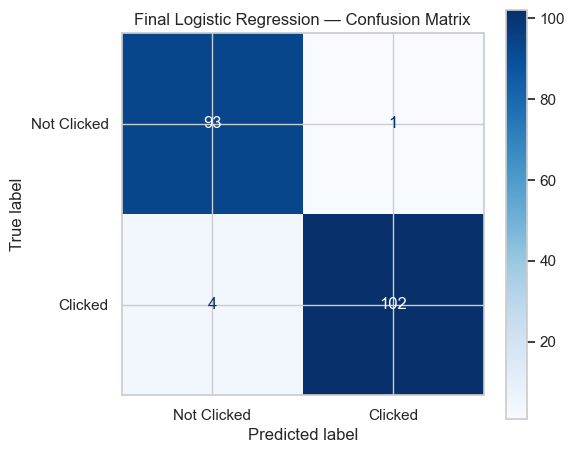

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=['Not Clicked', 'Clicked'],
    cmap='Blues',
    values_format='d',
    ax=ax
)

ax.set_title('Final Logistic Regression — Confusion Matrix')

plt.tight_layout()
plt.show()

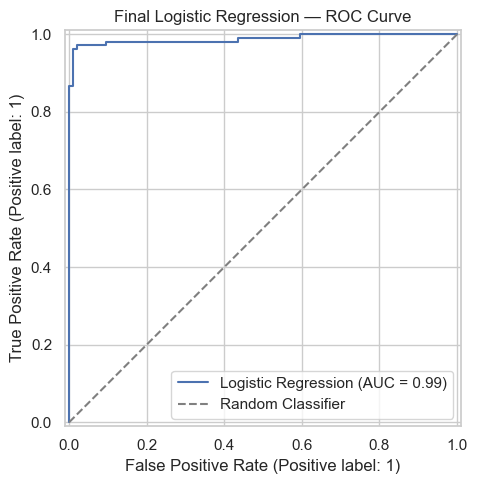

In [53]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_test_proba,
    name='Logistic Regression',
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

ax.set_title('Final Logistic Regression — ROC Curve')
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

### Final Test Evaluation Results

The final Logistic Regression pipeline was trained on 800 observations and evaluated on the untouched chronological test set containing 200 observations.

The model achieved the following results:

- Accuracy: 97.50%
- Precision: 99.03%
- Recall: 96.23%
- F1-score: 97.61%
- ROC-AUC: 98.82%

The confusion matrix showed:

- True Negatives (TN): 93
- False Positives (FP): 1
- False Negatives (FN): 4
- True Positives (TP): 102

Overall, the model correctly classified 195 out of 200 test observations.

The ROC curve demonstrated excellent discrimination between users who clicked on advertisements and those who did not.

The final test results were slightly higher than the initial validation results, although this difference should be interpreted cautiously because of the limited test sample size.

These findings suggest that Logistic Regression is an effective baseline approach for advertisement click prediction on this dataset.

The test set was evaluated only after model selection and final training were completed.

## Feature Interpretation

The final Logistic Regression model is interpreted by examining its learned coefficients.

The continuous numerical features were standardized during preprocessing, allowing their coefficients to represent changes in log-odds associated with a one-standard-deviation increase.

The Male feature was passed through without scaling, so its coefficient represents the difference between Male = 1 and Male = 0, holding other features constant.

Positive coefficients indicate higher predicted log-odds of clicking on an advertisement, while negative coefficients indicate lower predicted log-odds.

Coefficient magnitudes should be interpreted carefully, and the observed associations should not be considered causal effects.

In [54]:
# Extract trained classifier
lr_classifier = final_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = final_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Extract coefficients
coefficients = lr_classifier.coef_[0]

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Odds Ratio': np.exp(coefficients),
    'Absolute Coefficient': np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

display(feature_importance.round(4))

,Feature,Coefficient,Odds Ratio,Absolute Coefficient
0,num__Daily Time Spent on Site,-2.6858,0.0682,2.6858
3,num__Daily Internet Usage,-2.4750,0.0842,2.4750
2,num__Area Income,-1.4693,0.2301,1.4693
1,num__Age,1.2702,3.5617,1.2702
4,binary__Male,-0.2652,0.7671,0.2652


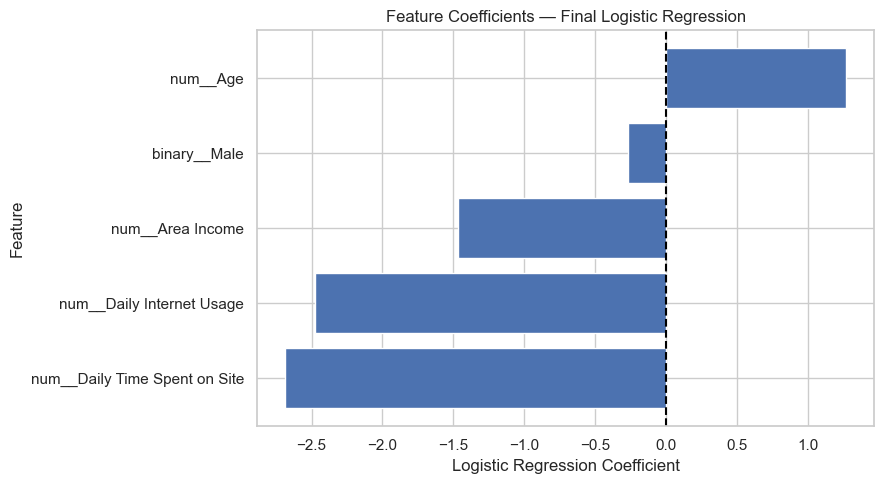

In [55]:
plot_data = feature_importance.sort_values(
    'Coefficient')

plt.figure(figsize=(9, 5))

plt.barh(plot_data['Feature'],plot_data['Coefficient'])

plt.axvline(x=0, color='black', linestyle='--')

plt.xlabel('Logistic Regression Coefficient')
plt.ylabel('Feature')
plt.title('Feature Coefficients — Final Logistic Regression')

plt.tight_layout()
plt.show()

### Logistic Regression Coefficient Interpretation

The final Logistic Regression model was interpreted using its learned coefficients and corresponding odds ratios.

Among the standardized numerical features, Daily Time Spent on Site and Daily Internet Usage had the largest absolute coefficients, at -2.6858 and -2.4750, respectively.

Both variables were negatively associated with advertisement clicking, holding the other predictors constant.

Area Income also showed a negative association with clicking (coefficient = -1.4693).

Age had a positive coefficient of 1.2702, corresponding to an odds ratio of 3.5617 for a one-standard-deviation increase.

The Male variable had a smaller negative coefficient of -0.2652, corresponding to an odds ratio of 0.7671 for Male = 1 compared with Male = 0.

The continuous features were standardized, while Male was left unscaled. Therefore, direct comparisons of coefficient magnitudes across all features should be interpreted cautiously.

These results describe predictive associations rather than causal relationships.

## Model Persistence

The final trained Logistic Regression pipeline is saved using joblib.

Saving the complete pipeline preserves both preprocessing and classification steps, ensuring that new observations are transformed consistently before prediction.

The saved model can be loaded later for inference without retraining.

In [60]:
import joblib

model_path = "advertisement_click_logistic_regression.pkl"

joblib.dump(final_model, model_path)

print(f"Model saved successfully: {model_path}")

Model saved successfully: advertisement_click_logistic_regression.pkl


In [61]:
model_path = "advertisement_click_logistic_regression.pkl"

joblib.dump(final_model, model_path)

print(f"Model saved successfully: {model_path}")

Model saved successfully: advertisement_click_logistic_regression.pkl


## Final Conclusion

This project developed and evaluated machine learning models to predict whether a user would click on an online advertisement based on demographic and behavioral information.

### Project Workflow

The analysis included:

1. Exploratory Data Analysis (EDA) to understand feature distributions, relationships, and class balance.
2. Feature Engineering to extract temporal information from timestamps.
3. Chronological splitting into training (64%), validation (16%), and testing (20%) datasets.
4. Training and comparison of eight classification algorithms:
   - Logistic Regression
   - Decision Tree
   - Random Forest
   - Support Vector Machine (SVM)
   - K-Nearest Neighbors (KNN)
   - Gradient Boosting
   - XGBoost
   - AdaBoost
5. Comparison of baseline and temporal feature sets.
6. Time-aware cross-validation to assess model stability.
7. Final model selection, evaluation, and interpretation.

### Final Model

Logistic Regression was selected because of its strong predictive performance, simplicity, interpretability, and consistent cross-validation results.

The final pipeline was trained on 800 observations using five baseline features.

### Final Test Performance

| Metric | Score |
|---|---|
| Accuracy | 97.50% |
| Precision | 99.03% |
| Recall | 96.23% |
| F1-score | 97.61% |
| ROC-AUC | 98.82% |

The